# Phenix - Lire les résultats du détecteur

Ce notebook explore une expérience **déjà entraînée**. Il ne réentraîne rien, ne charge pas le fichier joblib et ne déclenche aucune action Ansible.

**Installation :** placer ce fichier dans `backend/ML/notebooks/`, l’ouvrir dans VS Code et sélectionner un noyau Python. Exécuter les cellules dans l’ordre avec **Run All**.

Si nécessaire, installer dans le noyau choisi : `%pip install pandas==2.2.3 numpy==2.3.5 matplotlib ipykernel`. Cette installation concerne le notebook local ; elle ne modifie pas l’image Docker du détecteur. Le build Docker précédent n’installe pas ces bibliothèques sur Windows.

Le dossier lu par défaut est `backend/ML/experiments/local-v1`. Modifier `EXPERIMENT` ci-dessous pour une autre expérience. Les graphiques enregistrés ici correspondent aux fichiers `local-v1` partagés ; relancer pour afficher les fichiers de votre poste.


In [1]:
%pip install pandas==2.2.3 numpy==2.3.5 matplotlib ipykernel

  Using cached pandas-2.2.3-cp312-cp312-win_amd64.whl.metadata (19 kB)
Using cached pandas-2.2.3-cp312-cp312-win_amd64.whl (11.5 MB)
   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
   ------ --------------------------------- 2.1/12.8 MB 16.8 MB/s eta 0:00:01
   ------- -------------------------------- 2.4/12.8 MB 9.0 MB/s eta 0:00:02
   --------- ------------------------------ 2.9/12.8 MB 4.4 MB/s eta 0:00:03
   ----------- ---------------------------- 3.7/12.8 MB 4.5 MB/s eta 0:00:03
   ------------ --------------------------- 3.9/12.8 MB 4.3 MB/s eta 0:00:03
   -------------- ------------------------- 4.7/12.8 MB 3.7 MB/s eta 0:00:03
   --------------- ------------------------ 5.0/12.8 MB 3.3 MB/s eta 0:00:03
   ------------------ --------------------- 5.8/12.8 MB 3.5 MB/s eta 0:00:03
   ------------------- -------------------- 6.3/12.8 MB 3.4 MB/s eta 0:00:02
   --------------------- ------------------ 6.8/12.8 MB 3.3 MB/s eta 0:00:02
   ---------------------- 

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.19.0 requires numpy<2.2.0,>=1.26.0, but you have numpy 2.3.5 which is incompatible.

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

EXPERIMENT = "local-v1"
# Recherche le projet depuis la racine, backend/ML ou le dossier notebooks.
ML_ROOT = None
for parent in [Path.cwd(), *Path.cwd().parents]:
    for candidate in [parent, parent / "backend" / "ML"]:
        if (candidate / "experiments" / EXPERIMENT / "metrics.json").is_file():
            ML_ROOT = candidate
            break
    if ML_ROOT is not None:
        break
if ML_ROOT is None:
    raise FileNotFoundError("Expérience introuvable : placer ce notebook dans backend/ML/notebooks et vérifier EXPERIMENT.")

EXP_DIR = ML_ROOT / "experiments" / EXPERIMENT
metrics = json.loads((EXP_DIR / "metrics.json").read_text(encoding="utf-8"))
threshold = metrics["metadata"]["threshold"]
predictions = {}
for split in ["train", "calibration", "validation", "test"]:
    df = pd.read_csv(EXP_DIR / f"{split}_predictions.csv", parse_dates=["timestamp"])
    assert df.timestamp.is_unique, f"Dates dupliquées : {split}"
    assert df.is_anomaly.isin([0, 1]).all() and df.predicted_anomaly.isin([0, 1]).all()
    assert np.isfinite(df.anomaly_score).all()
    assert np.array_equal((df.anomaly_score > threshold).astype(int), df.predicted_anomaly)
    predictions[split] = df.sort_values("timestamp").reset_index(drop=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Expérience :", EXPERIMENT)
print("Seuil fixé pendant la calibration :", round(threshold, 6))
print("Variables du modèle :", ", ".join(metrics["metadata"]["features"]))


Expérience : local-v1
Seuil fixé pendant la calibration : 0.64714
Variables du modèle : req_per_sec, latency_ms, error_rate_pct, cpu_usage_pct, auth_failures_per_min


## 1. Comparer les périodes

**VP** : anomalie détectée ; **FP** : minute normale signalée ; **FN** : anomalie manquée ; **VN** : minute normale non signalée.

Précision = VP / (VP + FP). Rappel = VP / (VP + FN). Une ligne représente une minute, pas une attaque indépendante. Le train et la calibration ne sont pas des tests indépendants. Le rappel est non défini lorsqu’il n’y a aucune anomalie réelle.


In [3]:
summary = []
for split, df in predictions.items():
    y, p = df.is_anomaly, df.predicted_anomaly
    tp = int(((y == 1) & (p == 1)).sum())
    fp = int(((y == 0) & (p == 1)).sum())
    fn = int(((y == 1) & (p == 0)).sum())
    tn = int(((y == 0) & (p == 0)).sum())
    expected = metrics["splits"][split]
    for key, value in [("true_positive", tp), ("false_positive", fp), ("false_negative", fn), ("true_negative", tn)]:
        assert expected[key] == value, f"CSV et metrics.json différents : {split}/{key}"
    summary.append({"Période": split, "Minutes": len(df), "VP": tp, "FP": fp, "FN": fn, "VN": tn,
                    "Précision": tp / (tp + fp) if tp + fp else np.nan,
                    "Rappel": tp / (tp + fn) if tp + fn else np.nan,
                    "Minutes FP/jour observé": fp / (len(df) / 1440)})
summary = pd.DataFrame(summary).set_index("Période")
display(summary.round(3))


,Minutes,VP,FP,FN,VN,Précision,Rappel,Minutes FP/jour observé
Période,,,,,,,,
train,5760,0,45,0,5715,0.000,NaN,11.250
calibration,5760,30,29,0,5701,0.508,1.0,7.250
validation,4320,45,79,0,4196,0.363,1.0,26.333
test,4320,40,15,0,4265,0.727,1.0,5.000


## 2. Scores dans le temps

Le score est celui de la forêt, avec son signe inversé : **plus haut = plus inhabituel**, pas « probabilité d’attaque ». La ligne pointillée est le seuil déjà fixé. Les croix orange sont des fausses alertes ; les points violets sont des minutes réellement anormales selon le générateur.


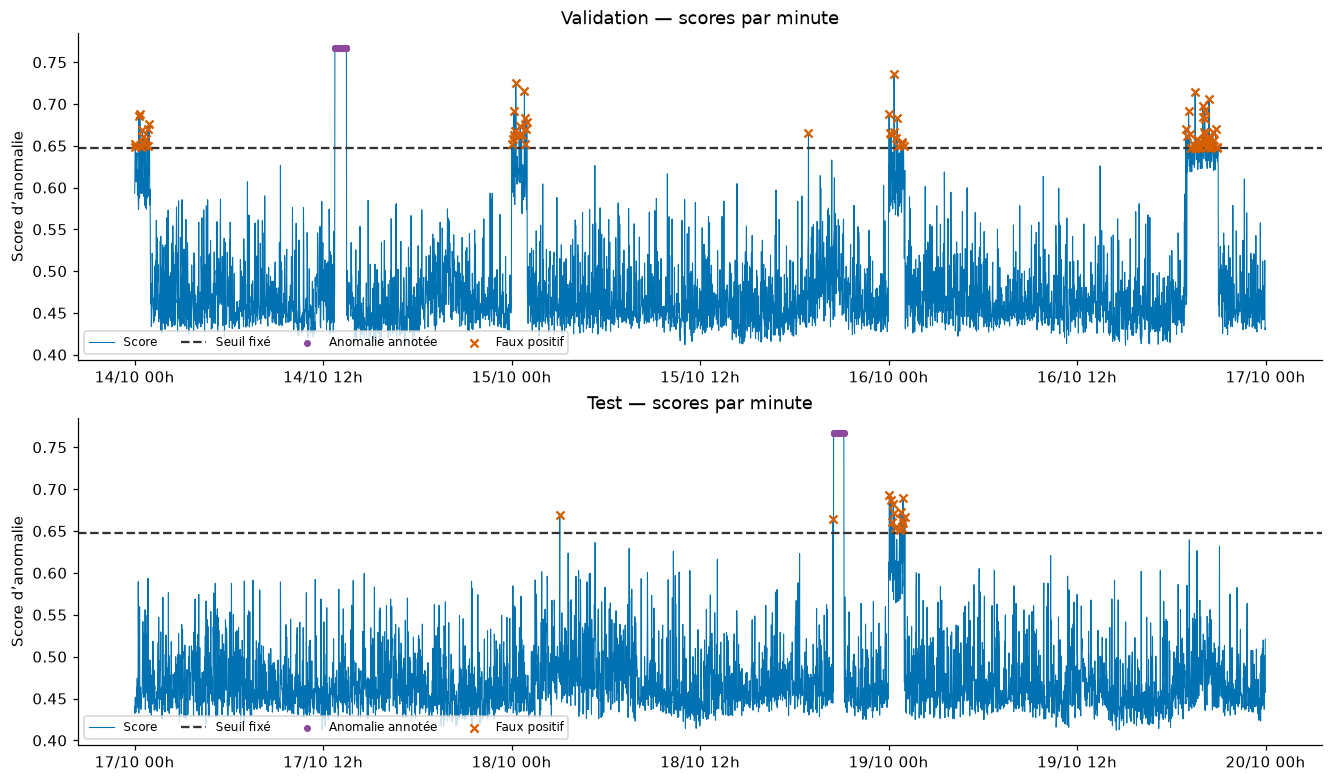

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), layout="constrained")
for ax, split in zip(axes, ["validation", "test"]):
    df = predictions[split]
    fp = df[(df.is_anomaly == 0) & (df.predicted_anomaly == 1)]
    actual = df[df.is_anomaly == 1]
    ax.plot(df.timestamp, df.anomaly_score, color="#0072B2", lw=0.7, label="Score")
    ax.axhline(threshold, color="#333333", ls="--", label="Seuil fixé")
    ax.scatter(actual.timestamp, actual.anomaly_score, color="#8B4A9C", s=13, label="Anomalie annotée", zorder=3)
    ax.scatter(fp.timestamp, fp.anomaly_score, color="#D55E00", marker="x", s=28, label="Faux positif", zorder=4)
    ax.set(title=f"{split.capitalize()} — scores par minute", ylabel="Score d’anomalie")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
    ax.legend(loc="lower left", ncol=4, fontsize=8)
plt.show()


## 3. Matrice de confusion du test

La matrice compte les minutes selon l’annotation et la décision du modèle. Elle complète les pourcentages : sur un jeu très déséquilibré, une forte exactitude globale peut masquer des anomalies manquées.


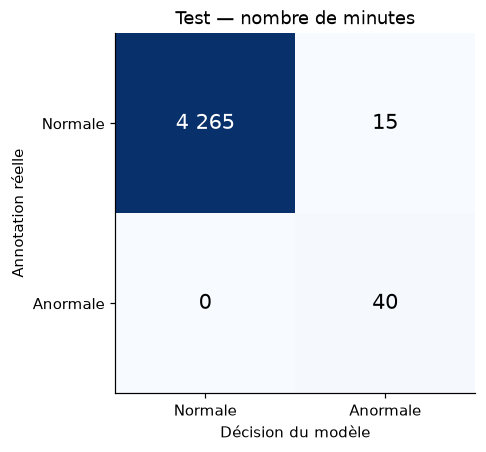

In [5]:
s = summary.loc["test"]
cm = np.array([[s.VN, s.FP], [s.FN, s.VP]], dtype=int)
fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
ax.imshow(cm, cmap="Blues")
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, f"{value:,}".replace(",", " "), ha="center", va="center",
            color="white" if value > cm.max() / 2 else "black", fontsize=14)
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Normale", "Anormale"],
       yticklabels=["Normale", "Anormale"], xlabel="Décision du modèle", ylabel="Annotation réelle",
       title="Test — nombre de minutes")
plt.show()


## 4. Examiner les fausses alertes de validation

Le CSV d’origine est joint aux scores par horodatage. Son empreinte doit correspondre à l’expérience. Le tableau affiche les dix faux positifs ayant les scores les plus élevés.

Ces valeurs aident à formuler des hypothèses ; elles ne sont ni une explication causale ni une mesure de l’importance des variables dans la forêt.


In [6]:
DATA_PATH = ML_ROOT / "data" / "alphapay_telemetry_fr_realistic.csv"
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == metrics["metadata"]["source_sha256"], "Le CSV source ne correspond pas à cette expérience."
telemetry = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
features = metrics["metadata"]["features"]
assert telemetry.timestamp.is_unique
joined = {}
for split, df in predictions.items():
    merged = df.merge(telemetry[["timestamp", *features]], on="timestamp", how="left", validate="one_to_one")
    assert not merged[features].isna().any().any(), "Mesures manquantes après jointure"
    joined[split] = merged

validation = joined["validation"]
false_positives = validation[(validation.is_anomaly == 0) & (validation.predicted_anomaly == 1)]
display(false_positives.nlargest(10, "anomaly_score")[["timestamp", "anomaly_score", *features]])
print("Fausses alertes de validation :", len(false_positives), "minutes")


,timestamp,anomaly_score,req_per_sec,latency_ms,error_rate_pct,cpu_usage_pct,auth_failures_per_min
2901,2026-10-16 00:21:00,0.735747,48.00,36.79,2.05,49.58,9
1456,2026-10-15 00:16:00,0.725170,48.00,38.33,2.20,52.00,5
1489,2026-10-15 00:49:00,0.714978,48.00,34.41,1.58,50.49,7
4051,2026-10-16 19:31:00,0.714587,60.36,41.89,2.08,58.39,1
4104,2026-10-16 20:24:00,0.705402,59.51,38.81,2.08,62.14,3
4080,2026-10-16 20:00:00,0.698028,57.39,38.65,1.88,57.60,0
4088,2026-10-16 20:08:00,0.693162,59.35,40.53,0.90,55.89,6
1449,2026-10-15 00:09:00,0.691842,48.00,37.90,2.20,49.86,1
4026,2026-10-16 19:06:00,0.691561,59.98,37.15,2.13,62.96,3
20,2026-10-14 00:20:00,0.688126,48.00,36.03,0.95,50.29,8


Fausses alertes de validation : 79 minutes


### Valeurs des mesures selon le résultat

Les boîtes comparent les minutes normales non signalées, les faux positifs et les minutes anormales de validation. Les points extrêmes sont masqués uniquement dans ce graphique ; ils restent dans les données. Les groupes ont des tailles très différentes.


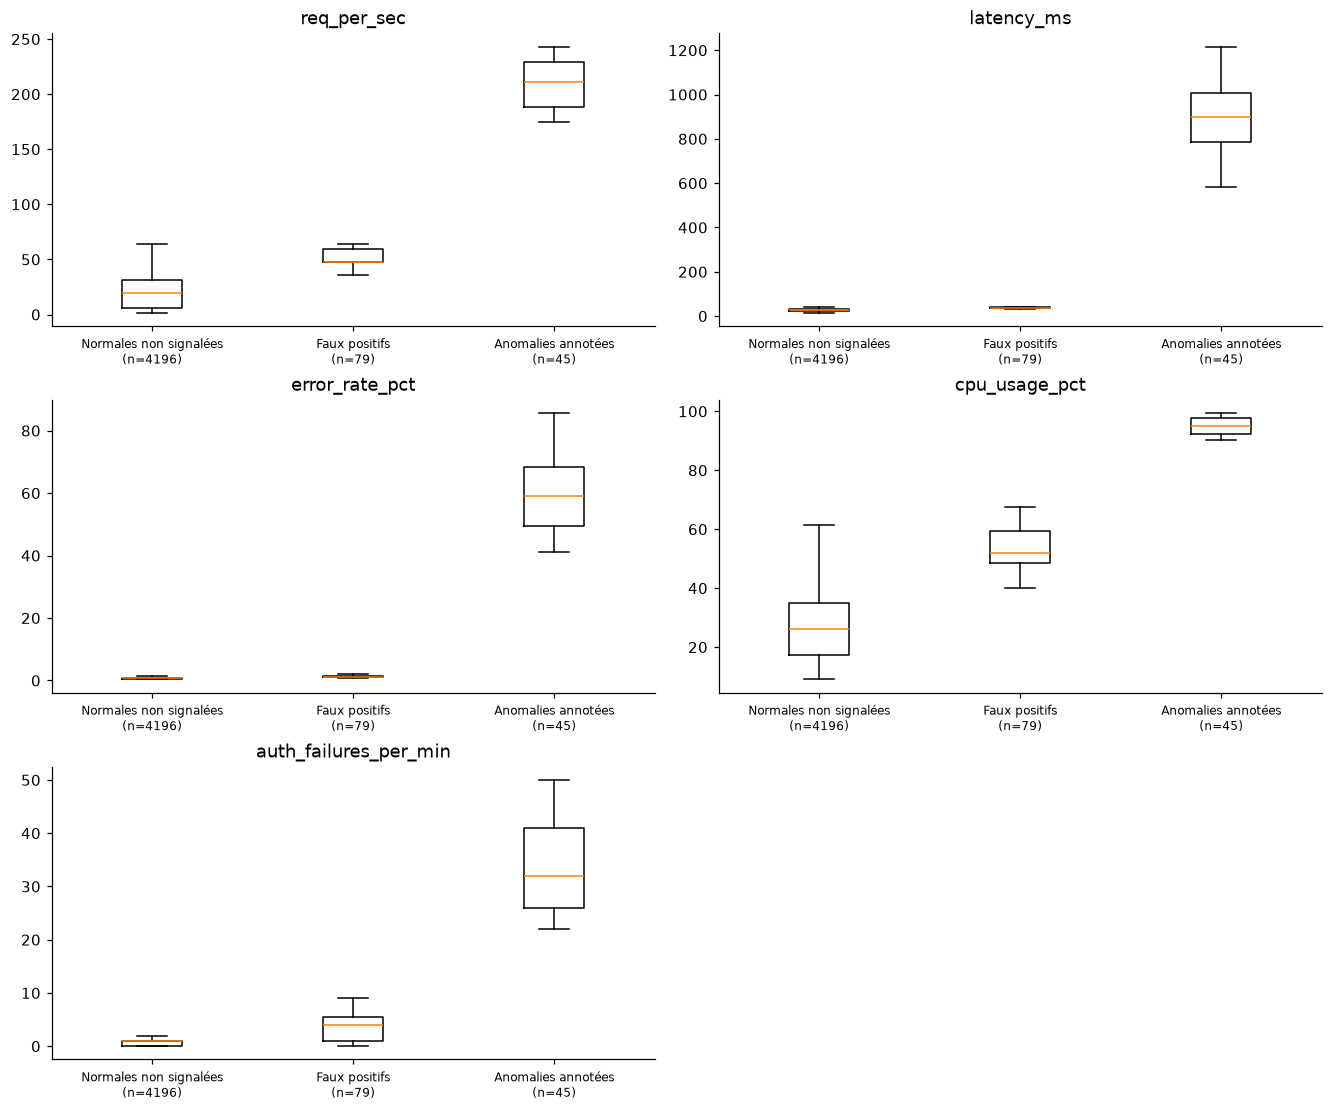

In [7]:
groups = [
    ("Normales non signalées", validation[(validation.is_anomaly == 0) & (validation.predicted_anomaly == 0)]),
    ("Faux positifs", false_positives),
    ("Anomalies annotées", validation[validation.is_anomaly == 1]),
]
fig, axes = plt.subplots(3, 2, figsize=(12, 10), layout="constrained")
for ax, feature in zip(axes.flat, features):
    values = [g[feature].to_numpy() if len(g) else np.array([np.nan]) for _, g in groups]
    ax.boxplot(values, showfliers=False)
    ax.set_xticks([1, 2, 3], [f"{name}\n(n={len(g)})" for name, g in groups], fontsize=8)
    ax.set_title(feature)
axes.flat[-1].set_visible(False)
plt.show()


## 5. Incidents et séquences de fausses alertes

Les épisodes ci-dessous sont issus des annotations du générateur. Le délai « 0 minute » signifie une détection dès la première observation annotée, pas une mesure de délai en direct. Les séquences de faux positifs regroupent seulement les minutes consécutives ; elles ne correspondent pas encore à des tickets d’incident ou des corrections.


In [8]:
episodes = []
for split in ["calibration", "validation", "test"]:
    for item in metrics["splits"][split]["episodes"]:
        episodes.append({"Période": split, **item})
display(pd.DataFrame(episodes))

fp_runs = []
for split in ["validation", "test"]:
    df = predictions[split].copy()
    mask = (df.is_anomaly == 0) & (df.predicted_anomaly == 1)
    df["run"] = mask.ne(mask.shift(fill_value=False)).cumsum()
    for _, block in df[mask].groupby("run"):
        fp_runs.append({"Période": split, "Début": block.timestamp.iloc[0], "Fin": block.timestamp.iloc[-1], "Minutes": len(block)})
fp_runs = pd.DataFrame(fp_runs)
display(fp_runs.groupby("Période").agg(Séquences=("Minutes", "size"), Minutes=("Minutes", "sum")))
display(fp_runs.sort_values("Minutes", ascending=False).head(10))


,Période,start,end,minutes,detected,delay_minutes
0,calibration,2026-10-10 03:15:00,2026-10-10 03:44:00,30,True,0
1,validation,2026-10-14 12:45:00,2026-10-14 13:29:00,45,True,0
2,test,2026-10-18 20:30:00,2026-10-18 21:09:00,40,True,0


,Séquences,Minutes
Période,,
test,12,15
validation,56,79


,Période,Début,Fin,Minutes
39,validation,2026-10-16 19:31:00,2026-10-16 19:35:00,5
45,validation,2026-10-16 20:06:00,2026-10-16 20:10:00,5
44,validation,2026-10-16 20:00:00,2026-10-16 20:03:00,4
4,validation,2026-10-14 00:30:00,2026-10-14 00:32:00,3
19,validation,2026-10-15 00:52:00,2026-10-15 00:54:00,3
55,validation,2026-10-16 20:53:00,2026-10-16 20:54:00,2
65,test,2026-10-19 00:50:00,2026-10-19 00:51:00,2
0,validation,2026-10-14 00:02:00,2026-10-14 00:03:00,2
52,validation,2026-10-16 20:37:00,2026-10-16 20:38:00,2
30,validation,2026-10-16 00:52:00,2026-10-16 00:53:00,2


## Notes d’observation

À compléter après lecture :
- Quelles périodes normales déclenchent des fausses alertes ?
- Les volumes et niveaux CPU de ces périodes sont-ils représentés dans le train ?
- Quelles hypothèses faudrait-il vérifier avec de nouvelles collectes ?

**Limites :** données synthétiques, trois épisodes au total et un seul dans le test. Le seuil est figé ici. Ne pas l’optimiser sur le test pour ensuite présenter ce même test comme inédit. Les graphiques ne démontrent pas qu’un pic est une attaque ni qu’un redémarrage est adapté. Aucun accès Prometheus/Loki ou Ansible n’est effectué.
